# CodeGuard AI · Experiment 04: Clean and explore the Python dataset (CVEfixes)

**Goal:** turn the extracted CVEfixes Python methods into a clean, documented dataset for Experiment 05.

**Before running:** download CVEfixes and run `python scripts/build_python_dataset.py` (see `Documents/Datasets_Guide.docx`).

**Steps**
1. Load the extracted methods
2. Look at a vulnerable/fixed pair
3. Find problems: missing values, duplicates, conflicting labels
4. Clean
5. Explore: class balance, CWE types, lengths, repository concentration
6. Which words change between vulnerable and fixed code?
7. Save the clean file

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/processed/python_functions.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7568, 9)


,id,func,target,method_name,cve_id,cwe_id,repo_url,commit_hash,filename
0,100033398365540,def get_search_columns_list(self):\n ...,0,get_search_columns_list,CVE-2023-34110,CWE-209,https://github.com/dpgaspar/Flask-AppBuilder,ae25ad4c87a9051ebe4a4e8f02aee73232642626,base.py
1,100074979643531,def enable_serve_artifacts(monkeypatch):\n ...,0,enable_serve_artifacts,CVE-2023-6831,"CWE-22,CWE-29",https://github.com/mlflow/mlflow,1da75dfcecd4d169e34809ade55748384e8af6c1,test_handlers.py
2,100085114878257,def _build_ssl_context(\n disable_ssl_certi...,1,_build_ssl_context,CVE-2021-21240,CWE-400,https://github.com/httplib2/httplib2,bd9ee252c8f099608019709e22c0d705e98d26bc,__init__.py
3,100089842633407,def test_serve_local(self) -> None:\n ...,1,test_serve_local,CVE-2023-22735,CWE-436,https://github.com/zulip/zulip,04cf68b45ebb5c03247a0d6453e35ffc175d55da,test_upload.py
4,100109100905010,def testUnravelIndexIntegerOverflow(self):\n...,0,testUnravelIndexIntegerOverflow,CVE-2022-21729,CWE-190,https://github.com/tensorflow/tensorflow,58b34c6c8250983948b5a781b426f6aa01fd47af,array_ops_test.py


## Step 2: One vulnerable method and its fixed version

In [2]:
pairs = df.groupby(["commit_hash", "filename", "method_name"])["target"].nunique()
pair_key = pairs[pairs == 2].index[0]
pair = df.set_index(["commit_hash", "filename", "method_name"]).loc[pair_key]
for _, row in pair.sort_values("target", ascending=False).iterrows():
    print("----- VULNERABLE (before fix) -----" if row["target"] == 1 else "----- FIXED (after fix) -----")
    print(row["func"][:600])
    print()

----- VULNERABLE (before fix) -----
def create_ssh_cred() -> None:
	from jinja2 import Environment, FileSystemLoader

	user_group = roxywi_common.get_user_group()
	name = common.checkAjaxInput(form.getvalue('new_ssh'))
	name = f'{name}_{user_group}'
	enable = common.checkAjaxInput(form.getvalue('ssh_enable'))
	group = common.checkAjaxInput(form.getvalue('new_group'))
	username = common.checkAjaxInput(form.getvalue('ssh_user'))
	password = common.checkAjaxInput(form.getvalue('ssh_pass'))
	page = common.checkAjaxInput(form.getvalue('page'))
	page = page.split("#")[0]
	lang = roxywi_common.get_user_lang()

	if username is None or n

----- FIXED (after fix) -----
def create_ssh_cred() -> None:
	from jinja2 import Environment, FileSystemLoader

	name = common.checkAjaxInput(form.getvalue('new_ssh'))
	enable = common.checkAjaxInput(form.getvalue('ssh_enable'))
	group = common.checkAjaxInput(form.getvalue('new_group'))
	group_name = sql.get_group_name_by_id(group)
	username = common.checkAjax

C:\Users\Dell\AppData\Local\Temp\ipykernel_31668\709452184.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  pair = df.set_index(["commit_hash", "filename", "method_name"]).loc[pair_key]


**Notice:** the two versions are often almost identical. The fix might be one added check. This is what makes the task hard for a model that only counts words.

## Step 3: Find problems

1. **Missing values.**
2. **Duplicates** (ignoring whitespace). If identical code has both labels, we cannot know which is right, so we drop all copies. A method that did not really change in the fix shows up exactly like this.
3. **Very short methods** (one-liners) carry almost no signal.

In [3]:
print("Missing values:")
print(df.isnull().sum())

df["code_key"] = df["func"].str.replace(r"\s+", "", regex=True)
groups = df.groupby("code_key")["target"].agg(["size", "nunique"])
print()
print("Duplicate groups:", (groups["size"] > 1).sum())
print("Groups with conflicting labels:", (groups["nunique"] > 1).sum())

Missing values:
id             0
func           0
target         0
method_name    0
cve_id         0
cwe_id         0
repo_url       0
commit_hash    0
filename       0
dtype: int64



Duplicate groups: 315
Groups with conflicting labels: 273


## Step 4: Clean

In [4]:
rows_before = len(df)
conflicting = groups[groups["nunique"] > 1].index
df = df[~df["code_key"].isin(conflicting)]              # same code, both labels -> unusable
df = df.drop_duplicates(subset=["code_key", "target"])  # keep one copy of exact repeats
df["n_lines"] = df["func"].str.count("\n") + 1
df = df[df["n_lines"] >= 3]                              # drop one-liners
df["cwe_id"] = df["cwe_id"].fillna("unknown")

print("Rows before:", rows_before)
print("Rows after: ", len(df))

Rows before: 7568
Rows after:  6627


## Step 5: Explore

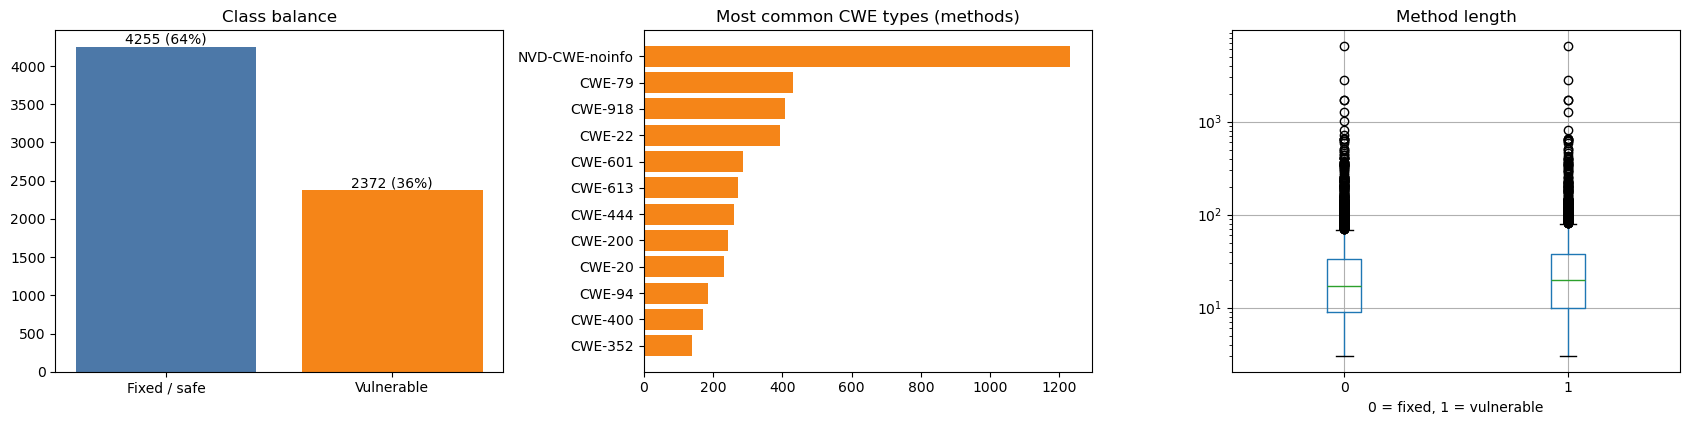

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df["target"].map({0: "Fixed / safe", 1: "Vulnerable"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#4C78A8", "#F58518"])
axes[0].set_title("Class balance")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v} ({v / len(df):.0%})", ha="center", va="bottom")

top_cwe = df["cwe_id"].str.split(",").explode().value_counts().head(12)
axes[1].barh(top_cwe.index[::-1], top_cwe.values[::-1], color="#F58518")
axes[1].set_title("Most common CWE types (methods)")

df.boxplot(column="n_lines", by="target", ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Method length")
axes[2].set_xlabel("0 = fixed, 1 = vulnerable")
fig.suptitle("")
plt.tight_layout()
plt.savefig("../artifacts/figures/python_dataset_eda.png", dpi=120)
plt.show()

In [6]:
repo_sizes = df["repo_url"].value_counts()
print("Repositories:", len(repo_sizes))
print("Share of methods from the 10 largest repositories:", f"{repo_sizes.head(10).sum() / len(df):.0%}")
repo_sizes.head(10)

Repositories: 425
Share of methods from the 10 largest repositories: 31%


repo_url
https://github.com/ikus060/rdiffweb         452
https://github.com/tensorflow/tensorflow    305
https://github.com/Pylons/waitress          208
https://github.com/janeczku/calibre-web     206
https://github.com/matrix-org/synapse       173
https://github.com/gradio-app/gradio        161
https://github.com/zenml-io/zenml           158
https://github.com/nautobot/nautobot        151
https://github.com/mlflow/mlflow            139
https://github.com/python/cpython           115
Name: count, dtype: int64

**What we found:** 425 repositories remain, and the 10 largest supply 31% of all methods (rdiffweb alone has 452). A random split would let the model learn these projects' style, so Experiment 05 splits by repository.

## Step 6: Which words change between vulnerable and fixed code?

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

counter = CountVectorizer(token_pattern=r"\b[A-Za-z_]\w+\b", min_df=20, binary=True)
X_counts = counter.fit_transform(df["func"])
words = np.array(counter.get_feature_names_out())
share_vuln = np.asarray(X_counts[df["target"].values == 1].mean(axis=0)).ravel()
share_safe = np.asarray(X_counts[df["target"].values == 0].mean(axis=0)).ravel()
diff = pd.Series(share_vuln - share_safe, index=words)
print("More common in VULNERABLE methods:")
print(diff.nlargest(15).round(3).to_string())
print()
print("More common in FIXED methods:")
print(diff.nsmallest(15).round(3).to_string())

More common in VULNERABLE methods:
if         0.073
return     0.071
else       0.058
join       0.057
for        0.051
none       0.051
in         0.047
and        0.045
get        0.045
or         0.039
data       0.039
add        0.038
int        0.036
request    0.034
append     0.032

More common in FIXED methods:
with                   -0.031
invalidargumenterror   -0.027
commit                 -0.025
assertraisesregex      -0.025
errors                 -0.021
must                   -0.021
evaluate               -0.020
pytest                 -0.018
client                 -0.018
raises                 -0.016
valueerror             -0.016
test                   -0.016
return_value           -0.015
assert                 -0.015
be                     -0.015


**What we found:** the differences are small (at most about 7 percentage points).
- Words more common in **vulnerable** methods are mostly generic control flow (`if`, `return`, `else`, `for`): vulnerable methods are longer on average.
- Words more common in **fixed** methods are mostly **test vocabulary** (`assertRaisesRegex`, `pytest`, `raises`, `assert`, `test`). Fix commits often *add new test methods*, and a method that only exists after the fix is labelled 0.

This is a **shortcut**: a model can learn "looks like a test → safe" instead of "unsafe pattern → vulnerable". Of 4,992 distinct methods, only 2,363 have both a before and an after version; the rest exist on one side only.

## Step 7: Save the clean file

In [8]:
columns = ["id", "func", "target", "method_name", "cve_id", "cwe_id", "repo_url", "commit_hash", "filename", "n_lines"]
df[columns].to_csv("../datasets/processed/python_functions_clean.csv", index=False)
print("Saved datasets/processed/python_functions_clean.csv with", len(df), "methods")

Saved datasets/processed/python_functions_clean.csv with 6627 methods


## Summary

| Item | Value |
|---|---|
| Source | CVEfixes v1.0.8 (MD5 verified), Python files only |
| Python methods extracted | 7,568 (2,775 before fix · 4,793 after fix) |
| Repositories · CVEs | 428 · 840 |
| Duplicate groups (whitespace-insensitive) | 315, of which 273 have conflicting labels |
| Removed (conflicting duplicates, repeats, one-liners) | 941 |
| **Clean methods** | **6,627** (2,372 vulnerable = 36% · 4,255 fixed = 64%) |
| Repositories after cleaning | 425 (top 10 = 31% of methods) |
| Most common CWE labels | NVD-CWE-noinfo, CWE-918 (SSRF), CWE-79 (XSS), CWE-22 (path traversal), CWE-601 (open redirect) |

**Limits to remember**
1. Labels come from fix commits. Many vulnerable/fixed pairs are almost identical (273 duplicate groups even had *both* labels: the method did not change in the fix).
2. Methods that exist only after the fix are mostly **new tests** labelled 0, which gives a model a shortcut (see Step 6).
3. The commonest CWE label is "NVD-CWE-noinfo" (no weakness type recorded).
4. Only methods are included; module-level code is not represented.